# Used Heavy Equipment Price Prediction and Market Intelligence
## Exploratory Data Analysis

**Dataset:** Kaggle *Blue Book for Bulldozers* — original training transactions (401,125 records, 1989–2011).  
**Objective:** Characterize historical auction prices, equipment categories, age–price associations, temporal trends, and data completeness to inform equipment valuation modelling.

### Reproduction
1. Obtain the original `Train.csv` from the dataset provider; place it under `data/raw/Train.csv` in the repository.
2. Open this notebook with the working directory set to the repository root or its `notebooks/` directory.
3. Run all cells from a fresh kernel. The source dataset is excluded from Git tracking.

**Scope and cautions:** Findings describe the recorded historical transactions, not the full equipment market. Prices are nominal (not inflation-adjusted), and associations are not causal effects.


In [1]:
# Load the original dataset without relying on any previous notebook state.
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Support notebooks opened from the repository root or notebooks/ folder.
working_directory = Path.cwd()
project_root = next(
    (candidate for candidate in [working_directory, working_directory.parent]
     if (candidate / "data" / "raw" / "Train.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "Place Train.csv under data/raw/ and launch Jupyter "
        "from the repository root or notebooks/ directory."
    )
data_path = project_root / "data" / "raw" / "Train.csv"
df = pd.read_csv(data_path, low_memory=False, parse_dates=["saledate"])
assert {"SalePrice", "ProductGroup", "YearMade", "saledate"}.issubset(df.columns)
print(f"Loaded {len(df):,} transactions and {len(df.columns)} columns")
print("Sale date range:", df["saledate"].min().date(), "to", df["saledate"].max().date())

Loaded 401,125 transactions and 53 columns
Sale date range: 1989-01-17 to 2011-12-30


## Selling-price distribution

In [2]:
# Select the target variable.
sale_prices = df["SalePrice"]

# Calculate the main descriptive statistics.
mean_price = sale_prices.mean()
median_price = sale_prices.median()
std_price = sale_prices.std()
min_price = sale_prices.min()
max_price = sale_prices.max()

# Calculate selected percentiles.
q1_price = sale_prices.quantile(0.25)
q3_price = sale_prices.quantile(0.75)

# Display the results.
print(f"Number of transactions: {sale_prices.count():,}")

print(f"Mean selling price: ${mean_price:,.2f}")

print(f"Median selling price: ${median_price:,.2f}")

print(f"Standard deviation: ${std_price:,.2f}")

print(f"Minimum selling price: ${min_price:,.2f}")

print(f"25th percentile: ${q1_price:,.2f}")

print(f"75th percentile: ${q3_price:,.2f}")

print(f"Maximum selling price: ${max_price:,.2f}")

Number of transactions: 401,125
Mean selling price: $31,099.71
Median selling price: $24,000.00
Standard deviation: $23,036.90
Minimum selling price: $4,750.00
25th percentile: $14,500.00
75th percentile: $40,000.00
Maximum selling price: $142,000.00


### Distribution chart

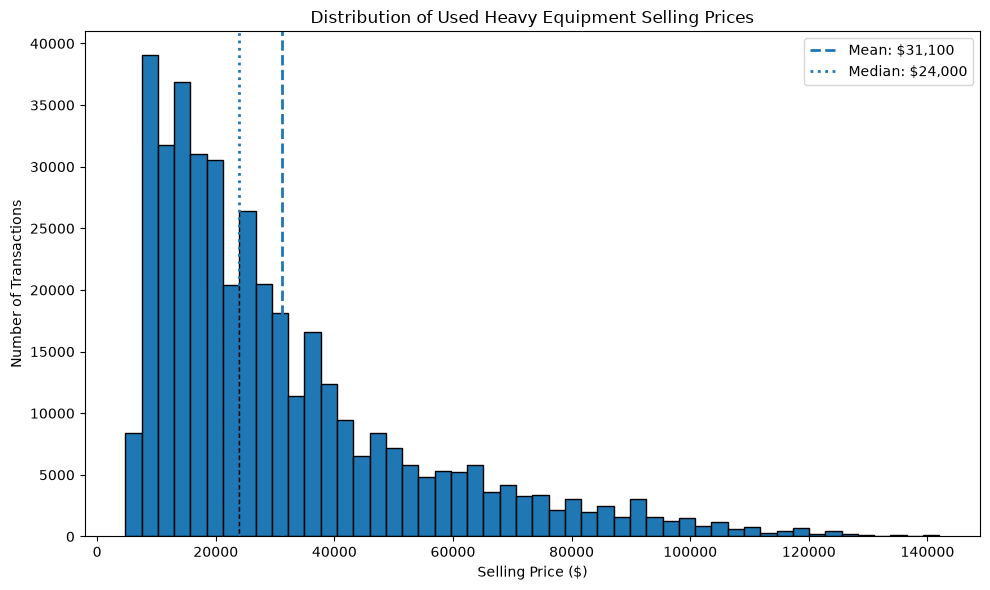

In [3]:
import matplotlib.pyplot as plt

# Create the histogram.
plt.figure(figsize=(10, 6))

plt.hist(
    df["SalePrice"],
    bins=50,
    edgecolor="black"
)

# Add a vertical line showing the mean.
plt.axvline(
    mean_price,
    linestyle="--",
    linewidth=2,
    label=f"Mean: ${mean_price:,.0f}"
)

# Add a vertical line showing the median.
plt.axvline(
    median_price,
    linestyle=":",
    linewidth=2,
    label=f"Median: ${median_price:,.0f}"
)

# Add descriptive labels.
plt.title("Distribution of Used Heavy Equipment Selling Prices")

plt.xlabel("Selling Price ($)")

plt.ylabel("Number of Transactions")

# Display the legend.
plt.legend()

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

### Skewness

In [4]:
# Calculate the skewness of selling prices.
price_skewness = df["SalePrice"].skew()

print(f"Selling price skewness: {price_skewness:.3f}")

# Interpret the sign of skewness.
if price_skewness > 0:

    print("The distribution is positively skewed.")

elif price_skewness < 0:

    print("The distribution is negatively skewed.")

else:

    print("The distribution is approximately symmetric.")

Selling price skewness: 1.525
The distribution is positively skewed.


**Interpretation.** Historical median sale price is $24,000, below the mean of $31,099.71. The distribution is right-skewed (skewness ≈ 1.525), with substantial price variation; a single typical price should not be applied to every machine.

## Category-level prices

In [5]:
import pandas as pd

# Group the dataset by equipment category.
# Calculate the number of transactions, mean price,
# median price, and standard deviation.
category_price_summary = (
    df.groupby("ProductGroup")["SalePrice"]
    .agg(
        Transactions="count",
        MeanPrice="mean",
        MedianPrice="median",
        StdPrice="std"
    )
    .reset_index()
)

# Sort equipment categories from the highest
# to the lowest median selling price.
category_price_summary = (
    category_price_summary
    .sort_values(
        by="MedianPrice",
        ascending=False
    )
)

# Display the results.
display(category_price_summary.round(2))

,ProductGroup,Transactions,MeanPrice,MedianPrice,StdPrice
1,MG,25489,47251.56,40000.0,32765.78
5,WL,71046,37052.46,32000.0,22596.33
4,TTT,80520,36158.41,29000.0,24338.87
3,TEX,101167,35666.12,29000.0,23618.22
0,BL,79415,20897.35,20500.0,7601.83
2,SSL,43488,10549.46,10000.0,3551.57


### Category chart

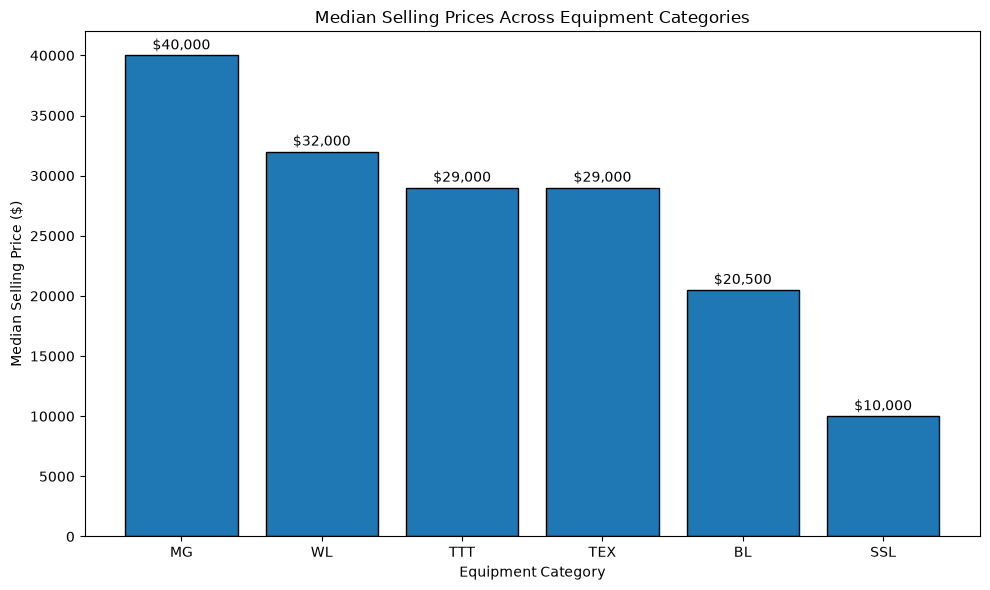

In [6]:
import matplotlib.pyplot as plt

# Create the figure.
plt.figure(figsize=(10, 6))

# Create a bar chart using the categories
# and their corresponding median prices.
plt.bar(
    category_price_summary["ProductGroup"],
    category_price_summary["MedianPrice"],
    edgecolor="black"
)

# Add a descriptive title.
plt.title(
    "Median Selling Prices Across Equipment Categories"
)

# Label the axes.
plt.xlabel("Equipment Category")

plt.ylabel("Median Selling Price ($)")

# Add median price labels above each bar.
for index, price in enumerate(
    category_price_summary["MedianPrice"]
):

    plt.text(
        index,
        price + 500,
        f"${price:,.0f}",
        ha="center"
    )

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

**Business interpretation.** Median prices differ sharply across groups: motor graders $40,000; wheel loaders $32,000; track type tractors and track excavators $29,000; backhoe loaders $20,500; skid steer loaders $10,000. Model category is an important candidate predictor, but these differences are not causal effects.

## Equipment-age preparation

In [7]:
import numpy as np
import pandas as pd

# Create a working copy to preserve the original dataset.
df_age = df.copy()

# Extract the year in which each machine was sold.
df_age["SaleYear"] = df_age["saledate"].dt.year

# Convert manufacturing year to numeric values.
df_age["YearMade_Clean"] = pd.to_numeric(
    df_age["YearMade"],
    errors="coerce"
)

# Treat placeholder manufacturing years as missing.
df_age.loc[
    df_age["YearMade_Clean"] == 1000,
    "YearMade_Clean"
] = np.nan

# Identify manufacturing years later than the sale year.
invalid_future_year = (
    df_age["YearMade_Clean"] > df_age["SaleYear"]
)

# Treat these inconsistent values as missing.
df_age.loc[
    invalid_future_year,
    "YearMade_Clean"
] = np.nan

# Calculate equipment age at the time of sale.
df_age["EquipmentAge"] = (
    df_age["SaleYear"] - df_age["YearMade_Clean"]
)

# Display the results.
print(
    "Missing equipment ages:",
    df_age["EquipmentAge"].isna().sum()
)

print(
    "Valid equipment ages:",
    df_age["EquipmentAge"].notna().sum()
)

print("\nEquipment age statistics:")

display(df_age["EquipmentAge"].describe())

Missing equipment ages: 38198
Valid equipment ages: 362927

Equipment age statistics:


count    362927.000000
mean         10.221003
std           7.568983
min           0.000000
25%           5.000000
50%           8.000000
75%          13.000000
max          92.000000
Name: EquipmentAge, dtype: float64

### Age and price correlations

In [8]:
# Select valid equipment-age and selling-price observations.
age_price_data = df_age[
    ["EquipmentAge", "SalePrice"]
].dropna()

# Calculate Pearson correlation.
pearson_correlation = (
    age_price_data["EquipmentAge"]
    .corr(
        age_price_data["SalePrice"],
        method="pearson"
    )
)

# Calculate Spearman correlation.
spearman_correlation = (
    age_price_data["EquipmentAge"]
    .corr(
        age_price_data["SalePrice"],
        method="spearman"
    )
)

# Display the results.
print(
    f"Pearson correlation: {pearson_correlation:.4f}"
)

print(
    f"Spearman correlation: {spearman_correlation:.4f}"
)

print(
    "Number of valid transactions:",
    len(age_price_data)
)

Pearson correlation: -0.2478
Spearman correlation: -0.2532
Number of valid transactions: 362927


### Age versus price chart

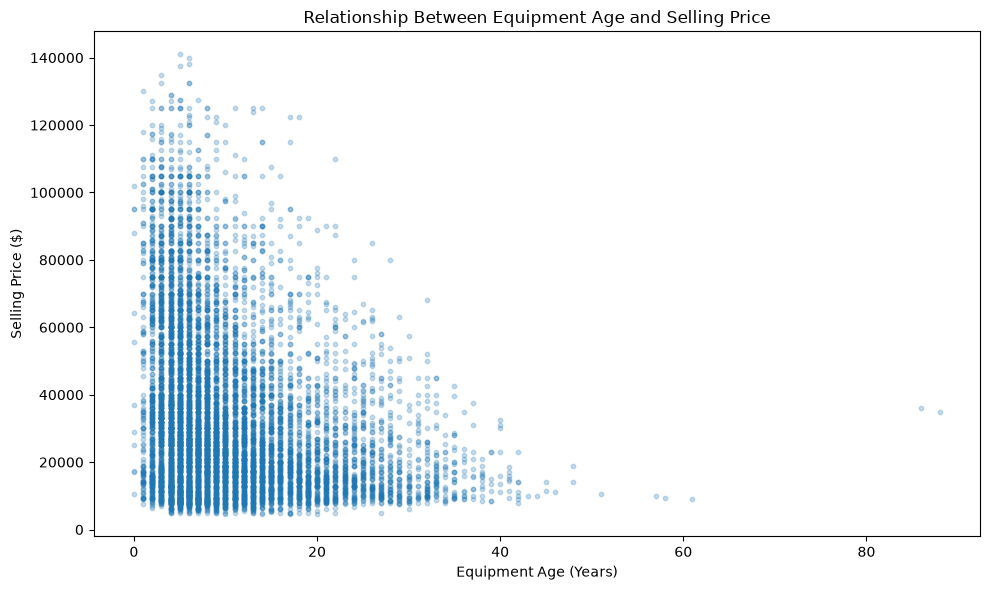

In [9]:
import matplotlib.pyplot as plt

# Select a reproducible random sample.
sample_size = min(
    10000,
    len(age_price_data)
)

age_price_sample = age_price_data.sample(
    n=sample_size,
    random_state=42
)

# Create the scatter plot.
plt.figure(figsize=(10, 6))

plt.scatter(
    age_price_sample["EquipmentAge"],
    age_price_sample["SalePrice"],
    alpha=0.25,
    s=10
)

# Add descriptive labels.
plt.title(
    "Relationship Between Equipment Age and Selling Price"
)

plt.xlabel("Equipment Age (Years)")

plt.ylabel("Selling Price ($)")

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

**Interpretation.** After treating placeholder manufacturing years and future manufacturing dates as missing, 38,198 transactions lack a valid age. With 362,927 valid ages, Pearson r ≈ −0.2478 and Spearman ρ ≈ −0.2532. Age alone does not determine price.

## Category-specific age–price relationships

In [10]:
import pandas as pd

# Select the variables required for the analysis.
# ProductGroup identifies the equipment category.
# EquipmentAge represents the machine's age at sale.
# SalePrice is the historical selling price.
category_age_data = df_age[
    ["ProductGroup", "EquipmentAge", "SalePrice"]
].dropna()

# Calculate Pearson correlation separately
# for each equipment category.
category_age_correlation = (
    category_age_data
    .groupby("ProductGroup")
    .apply(
        lambda group: group["EquipmentAge"].corr(
            group["SalePrice"],
            method="pearson"
        ),
        include_groups=False
    )
    .reset_index(name="PearsonCorrelation")
)

# Calculate the number of valid observations
# within each equipment category.
category_counts = (
    category_age_data
    .groupby("ProductGroup")
    .size()
    .reset_index(name="Transactions")
)

# Combine correlations and transaction counts.
category_age_summary = category_age_correlation.merge(
    category_counts,
    on="ProductGroup",
    how="left"
)

# Sort categories from strongest to weakest
# negative Pearson correlation.
category_age_summary = (
    category_age_summary
    .sort_values("PearsonCorrelation")
)

# Display the results.
display(category_age_summary.round(4))

,ProductGroup,PearsonCorrelation,Transactions
1,MG,-0.6788,22640
0,BL,-0.6573,74613
5,WL,-0.5293,64216
2,SSL,-0.4686,39481
4,TTT,-0.4003,73452
3,TEX,-0.3962,88525


### Category correlations chart

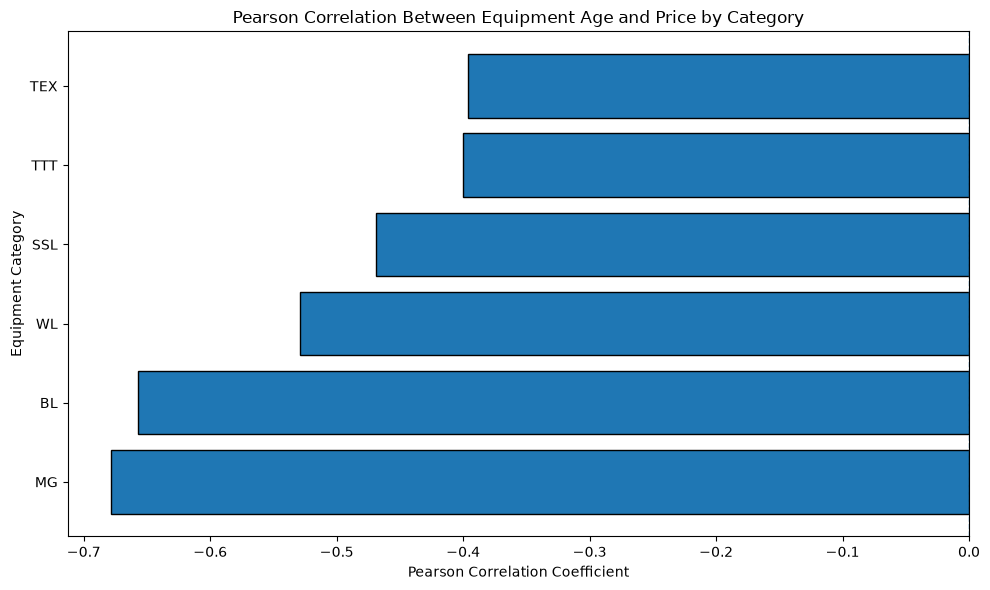

In [11]:
import matplotlib.pyplot as plt

# Create the chart.
plt.figure(figsize=(10, 6))

# Plot Pearson correlations horizontally.
plt.barh(
    category_age_summary["ProductGroup"],
    category_age_summary["PearsonCorrelation"],
    edgecolor="black"
)

# Add a vertical reference line at zero.
plt.axvline(
    x=0,
    linestyle="--",
    linewidth=1
)

# Add a descriptive title.
plt.title(
    "Pearson Correlation Between Equipment Age and Price by Category"
)

# Label the axes.
plt.xlabel("Pearson Correlation Coefficient")

plt.ylabel("Equipment Category")

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

**Interpretation.** Negative age–price correlations are stronger within categories (e.g., motor graders r ≈ −0.679 and backhoe loaders r ≈ −0.657) than in the pooled data. Category composition affects the aggregate association.

## Historical trends

In [12]:
import pandas as pd

# Create a separate copy for historical trend analysis.
# This protects the original dataset.
df_trends = df.copy()

# Extract the year of each equipment sale.
df_trends["SaleYear"] = df_trends["saledate"].dt.year

# Group equipment transactions by sale year.
annual_price_summary = (
    df_trends
    .groupby("SaleYear")
    .agg(
        Transactions=("SalePrice", "count"),
        MeanPrice=("SalePrice", "mean"),
        MedianPrice=("SalePrice", "median")
    )
    .reset_index()
    .sort_values("SaleYear")
)

# Display the annual summary.
display(annual_price_summary.round(2))

,SaleYear,Transactions,MeanPrice,MedianPrice
0,1989,4806,28452.90,21000.0
1,1990,4529,30878.36,22500.0
2,1991,5109,31268.91,23000.0
3,1992,5519,28565.31,21000.0
4,1993,6303,29922.24,22500.0
5,1994,7929,31089.37,23000.0
6,1995,8530,29062.07,21000.0
7,1996,8829,30589.42,23000.0
8,1997,9785,30767.69,23000.0
9,1998,13046,31578.17,24500.0


### Annual median selling prices

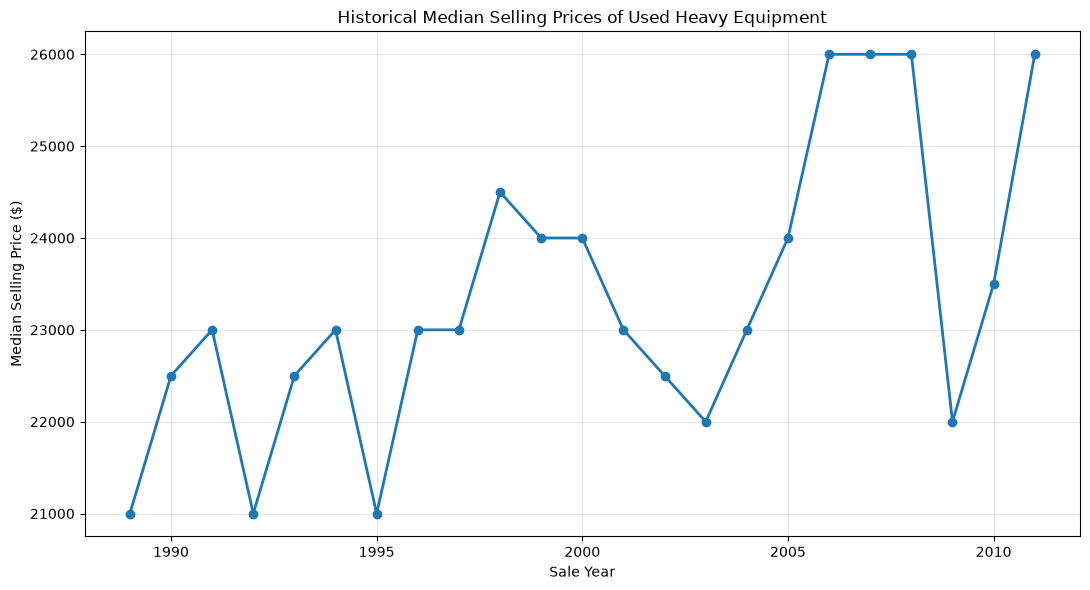

In [13]:
import matplotlib.pyplot as plt

# Create the figure.
plt.figure(figsize=(11, 6))

# Plot annual median selling prices.
plt.plot(
    annual_price_summary["SaleYear"],
    annual_price_summary["MedianPrice"],
    marker="o",
    linewidth=2
)

# Add a descriptive title.
plt.title(
    "Historical Median Selling Prices of Used Heavy Equipment"
)

# Label the axes.
plt.xlabel("Sale Year")
plt.ylabel("Median Selling Price ($)")

# Add a grid to improve readability.
plt.grid(
    alpha=0.3
)

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

### Annual transaction volume

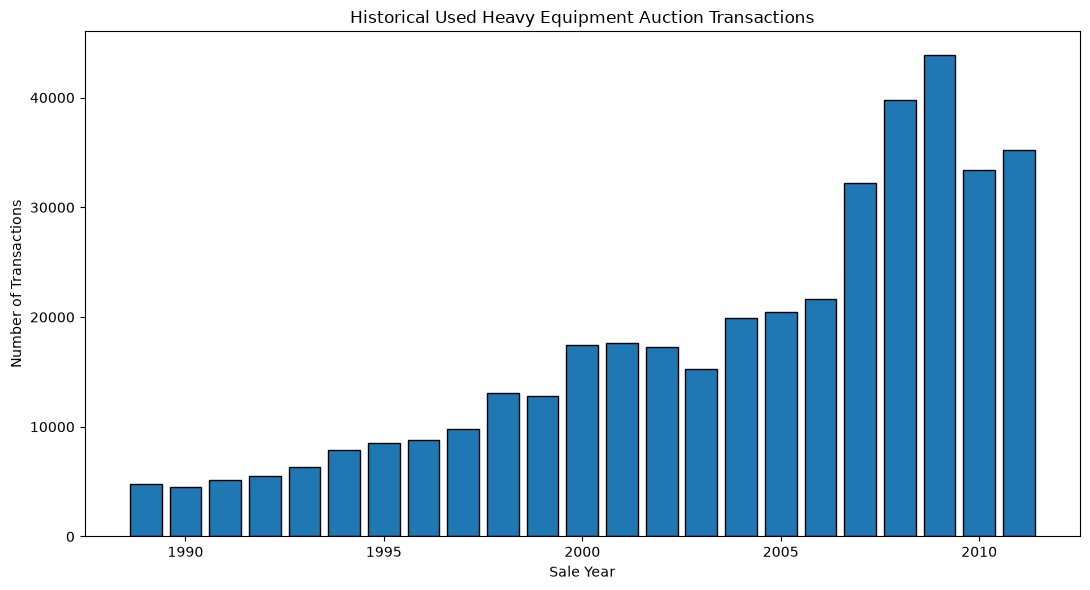

In [14]:
import matplotlib.pyplot as plt

# Create the figure.
plt.figure(figsize=(11, 6))

# Plot the number of transactions per year.
plt.bar(
    annual_price_summary["SaleYear"],
    annual_price_summary["Transactions"],
    edgecolor="black"
)

# Add a title.
plt.title(
    "Historical Used Heavy Equipment Auction Transactions"
)

# Label the axes.
plt.xlabel("Sale Year")
plt.ylabel("Number of Transactions")

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

**Interpretation.** Annual transaction medians fluctuate (2008: $26,000; 2009: $22,000; 2011: $26,000). These are nominal, unadjusted observed medians, not quality-adjusted equipment price indices. Temporal variation motivates chronological validation.

## Missing-value analysis

In [15]:
import pandas as pd

# Calculate the number of missing values in every column.
missing_counts = df.isna().sum()

# Calculate the percentage of missing values.
missing_percentages = (
    missing_counts / len(df)
) * 100

# Combine the results into a summary table.
missing_summary = pd.DataFrame({
    "MissingCount": missing_counts,
    "MissingPercentage": missing_percentages
})

# Sort columns from the highest to lowest
# percentage of missing values.
missing_summary = (
    missing_summary
    .sort_values(
        by="MissingPercentage",
        ascending=False
    )
)

# Display the 15 columns with the most missing values.
display(missing_summary.head(15).round(2))

,MissingCount,MissingPercentage
Pushblock,375906,93.71
Tip_Control,375906,93.71
Enclosure_Type,375906,93.71
Engine_Horsepower,375906,93.71
Blade_Extension,375906,93.71
Blade_Width,375906,93.71
Scarifier,375895,93.71
Grouser_Tracks,357763,89.19
Hydraulics_Flow,357763,89.19
Coupler_System,357667,89.17


### Most incomplete columns

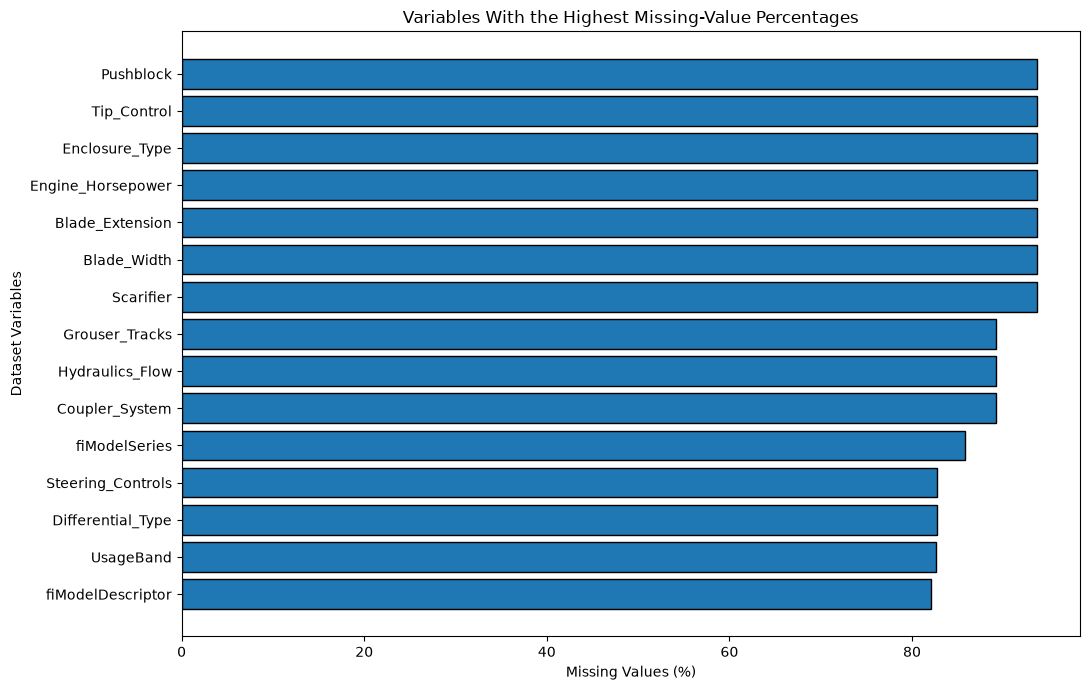

In [16]:
import matplotlib.pyplot as plt

# Select the 15 columns with the highest missing percentages.
top_missing = missing_summary.head(15)

# Create the horizontal bar chart.
plt.figure(figsize=(11, 7))

plt.barh(
    top_missing.index,
    top_missing["MissingPercentage"],
    edgecolor="black"
)

# Reverse the y-axis so the most incomplete
# variable appears at the top.
plt.gca().invert_yaxis()

# Add descriptive labels.
plt.title("Variables With the Highest Missing-Value Percentages")

plt.xlabel("Missing Values (%)")

plt.ylabel("Dataset Variables")

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

### Missingness in predictors

In [17]:
# Create a copy containing key equipment characteristics.
key_features = df[
    [
        "ProductGroup",
        "ModelID",
        "ProductSize",
        "YearMade",
        "MachineHoursCurrentMeter"
    ]
].copy()

# Replace the original manufacturing-year column
# with the cleaned manufacturing-year variable defined above.
key_features["YearMade_Clean"] = df_age["YearMade_Clean"]

# Calculate the missing percentage for each feature.
key_feature_missingness = (
    key_features.isna().mean() * 100
)

# Sort from highest to lowest missingness.
key_feature_missingness = (
    key_feature_missingness
    .sort_values(ascending=False)
)

# Display the results.
display(
    key_feature_missingness
    .to_frame(name="MissingPercentage")
    .round(2)
)

,MissingPercentage
MachineHoursCurrentMeter,64.41
ProductSize,52.55
YearMade_Clean,9.52
ProductGroup,0.00
ModelID,0.00
YearMade,0.00


**Data quality.** `MachineHoursCurrentMeter` is missing for ≈64.41% of records and `ProductSize` for ≈52.55%. The raw `YearMade` contains placeholder values not represented as NaN; cleaned manufacturing years are missing for ≈9.52%. Missing is not equivalent to zero.

## Missing ProductSize by category

In [18]:
import pandas as pd

# Create a copy containing the relevant variables.
product_size_data = df[
    ["ProductGroup", "ProductSize"]
].copy()

# Create an indicator showing whether ProductSize is missing.
# True represents a missing ProductSize value.
product_size_data["ProductSizeMissing"] = (
    product_size_data["ProductSize"].isna()
)

# Group transactions by equipment category.
product_size_missing_summary = (
    product_size_data
    .groupby("ProductGroup")
    .agg(
        Transactions=("ProductSizeMissing", "size"),
        MissingCount=("ProductSizeMissing", "sum"),
        MissingPercentage=("ProductSizeMissing", "mean")
    )
    .reset_index()
)

# Convert the missing proportion into a percentage.
product_size_missing_summary["MissingPercentage"] *= 100

# Sort categories from highest to lowest missingness.
product_size_missing_summary = (
    product_size_missing_summary
    .sort_values(
        "MissingPercentage",
        ascending=False
    )
)

# Display the results.
display(product_size_missing_summary.round(2))

,ProductGroup,Transactions,MissingCount,MissingPercentage
0,BL,79415,79415,100.00
1,MG,25489,25489,100.00
2,SSL,43488,43488,100.00
4,TTT,80520,39405,48.94
5,WL,71046,22823,32.12
3,TEX,101167,155,0.15


### ProductSize missingness chart

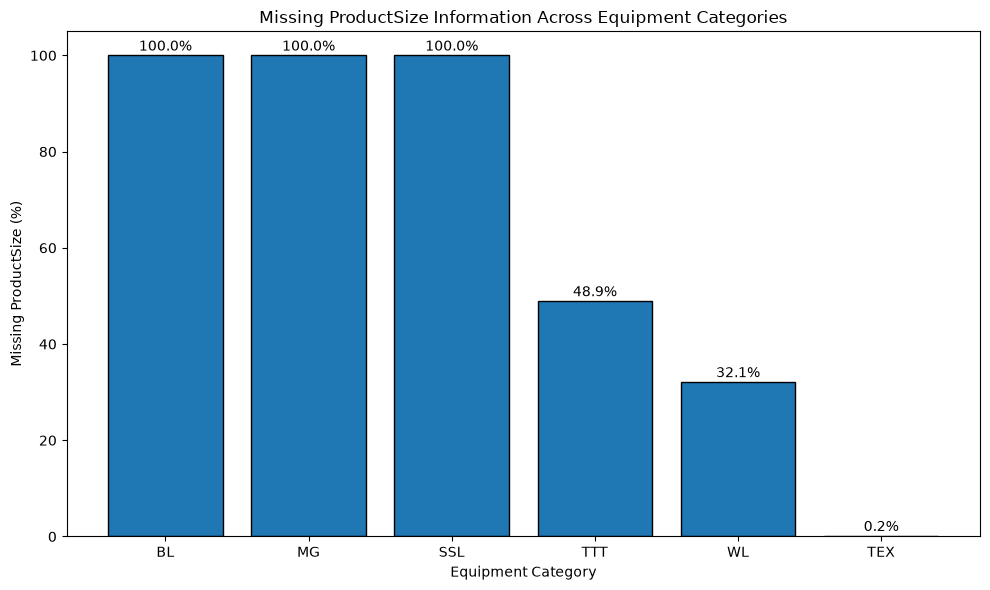

In [19]:
import matplotlib.pyplot as plt

# Create the figure.
plt.figure(figsize=(10, 6))

# Plot missing percentages by category.
plt.bar(
    product_size_missing_summary["ProductGroup"],
    product_size_missing_summary["MissingPercentage"],
    edgecolor="black"
)

# Add percentage labels above the bars.
for index, percentage in enumerate(
    product_size_missing_summary["MissingPercentage"]
):

    plt.text(
        index,
        percentage + 1,
        f"{percentage:.1f}%",
        ha="center"
    )

# Add a descriptive title.
plt.title(
    "Missing ProductSize Information Across Equipment Categories"
)

# Label the axes.
plt.xlabel("Equipment Category")

plt.ylabel("Missing ProductSize (%)")

# Display percentages from 0 to 105.
plt.ylim(0, 105)

# Improve the layout.
plt.tight_layout()

# Display the chart.
plt.show()

**Category-specific missingness.** `ProductSize` is absent for all backhoe loader, motor grader, and skid steer loader records, versus ≈0.15% of track excavator records. The absence may indicate category-specific collection practices; it should not be interpreted as a measured machine size.

## Conclusions and implications for modelling

- **Prices are heterogeneous:** Median selling price is $24,000 overall, but varies from $10,000 for skid steer loaders to $40,000 for motor graders. A single global price benchmark is inadequate for category-specific valuation.
- **Age is informative, but not sufficient:** The overall Pearson age–price correlation is approximately −0.248. Associations are more negative within each category, supporting inclusion of equipment category and age together in predictive models. Correlation is not a depreciation-rate estimate.
- **Observed prices shift over time:** Annual median transaction prices fluctuated, including a decline from $26,000 in 2008 to $22,000 in 2009. Chronological model validation is more appropriate than relying only on random splits.
- **Missingness is substantial and structured:** Operating hours and ProductSize have high missingness; all records in some equipment categories lack ProductSize. Invalid manufacturing-year codes require explicit treatment. Dropping every incomplete row would discard a large share of data.

### Limitations

The observations are historical and may not represent contemporary resale values. Differences between periods and categories may reflect changes in the mix of equipment sold, not only like-for-like prices. Data completeness varies by attribute and category. This notebook does not infer causal effects or establish future prediction accuracy.

### Next stage

Document validated preprocessing rules and feature engineering in dedicated, reusable code. Model training and evaluation must apply time-aware splits and fit learned preprocessing steps on training data only.
